# 4.11 결측 분포와 범주별 관측 수 탐색

churn.csv는 1200행입니다. 난수 시드 20261016의 완전한 교육용 합성 고객 데이터. 실제 고객 자료를 복사·익명화한 것이 아니며 개인과 연결되지 않음. SYN 식별자는 생성 행 번호. 요금은 가상 단위. churn=1은 생성 확률에 따라 표집한 가상 이탈. 실제 고객 행동이나 기업 성능을 뜻하지 않는다.

선정 이유: 수치·범주·결측이 함께 있는 자료라 열별 결측과 고객 유형별 관측 수를 비교할 수 있습니다. 행 삭제가 어떤 표본을 제외하는지 확인하기 위해 선택했습니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"sec_11_missingness"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.

변수 f를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 missing를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 missing.to_csv(OUT/"missingness.csv",header=["missing_fraction"]) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 missing.plot.bar(ax=axes[0],color=".65",edgecolor="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[0].set(ylabel="Missing fraction",title="Missing values") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

변수 counts를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 axes[1].bar(np.arange(len(counts)),counts.values,color=".7",edgecolor="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].set_xticks(np.arange(len(counts)),[f"C{i}" for i in range(len(counts))]) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].set(ylabel="Rows",title="Contract frequency") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

{
  "rows": 1200,
  "duplicate_rows": 0,
  "missing_fraction": {
    "total_charge": 0.016666666666666666,
    "monthly_charge": 0.016666666666666666,
    "support": 0.016666666666666666,
    "customer_id": 0.0,
    "age": 0.0,
    "tenure": 0.0,
    "contract": 0.0,
    "internet": 0.0,
    "ebilling": 0.0,
    "churn": 0.0
  },
  "contract_codes": {
    "C0": "monthly",
    "C1": "one_year",
    "C2": "two_year"
  }
}


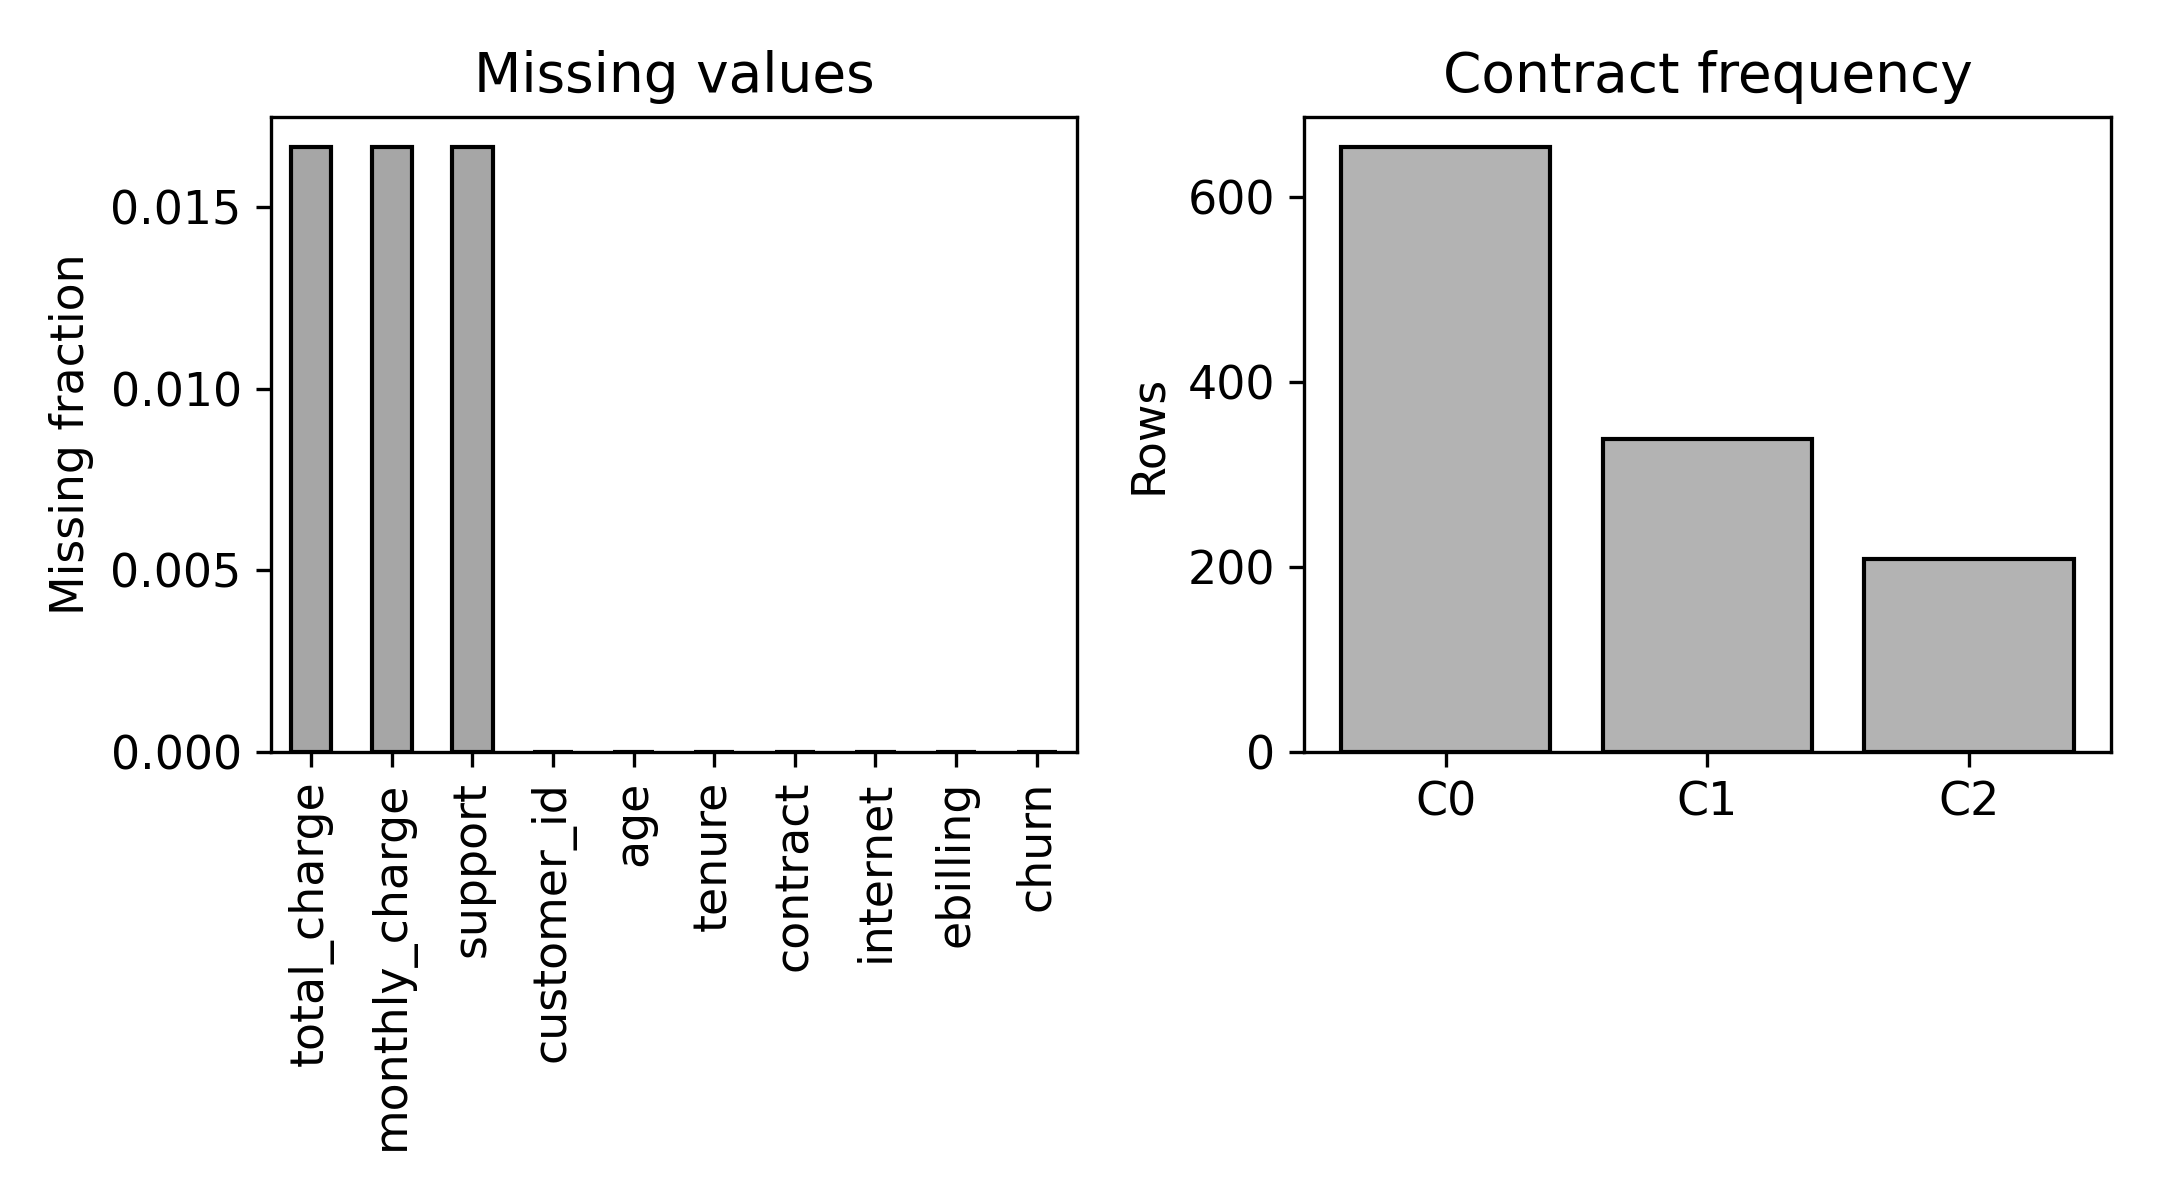

In [5]:
# 쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.
f=pd.read_csv(DATA/"churn.csv")

# 변수 f를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
f["total_charge"]=pd.to_numeric(f.total_charge,errors="coerce")

# 변수 missing를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
missing=f.isna().mean().sort_values(ascending=False)

# 앞 셀의 값을 사용해 missing.to_csv(OUT/"missingness.csv",header=["missing_fraction"]) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
missing.to_csv(OUT/"missingness.csv",header=["missing_fraction"])

# 변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fig,axes=plt.subplots(1,2,figsize=(7.2,4))

# 앞 셀의 값을 사용해 missing.plot.bar(ax=axes[0],color=".65",edgecolor="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
missing.plot.bar(ax=axes[0],color=".65",edgecolor="black")

# 앞 셀의 값을 사용해 axes[0].set(ylabel="Missing fraction",title="Missing values") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].set(ylabel="Missing fraction",title="Missing values")

# 변수 counts를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
counts=f.contract.fillna("MISSING").value_counts()

# 앞 셀의 값을 사용해 axes[1].bar(np.arange(len(counts)),counts.values,color=".7",edgecolor="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].bar(np.arange(len(counts)),counts.values,color=".7",edgecolor="black")

# 앞 셀의 값을 사용해 axes[1].set_xticks(np.arange(len(counts)),[f"C{i}" for i in range(len(counts))]) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].set_xticks(np.arange(len(counts)),[f"C{i}" for i in range(len(counts))])

# 앞 셀의 값을 사용해 axes[1].set(ylabel="Rows",title="Contract frequency") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].set(ylabel="Rows",title="Contract frequency")

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"missingness")

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"missingness",{"rows":len(f),"duplicate_rows":int(f.duplicated().sum()),
    "missing_fraction":missing.to_dict(),"contract_codes":{
    f"C{i}":str(c) for i,c in enumerate(counts.index)}})

## 그림과 결과 해석

왼쪽 분모는 전체 행 수다. 오른쪽 C0 등은 긴 범주명의 표시용 코드이며 의미는 JSON의 contract_codes에서 확인한다.

값의 부재 원인은 표만으로 알 수 없다. 결측률이 낮다고 무작위 결측이라고 단정하지 않는다.